# Questionário 7
Selecione 3 redes biológicas, 3 redes sociais e 3 redes tecnológicas.

Faça a classificação das redes selecionadas usando os modelos e medidas que aprendemos na aula (grafos aleatórios, small-world, Barabási-Albert, Waxman, etc). Não se esqueça de selecionar o mesmo N e grau médio que a rede original na construção dos modelos. Verifique qual o modelo mais adequado para cada rede.

> Hipótese: redes do mesmo tipo (biológica, social e tecnológica) seguem o mesmo modelo.
Verifique se essa hipótese é verdadeira.

Use um método de classificação que achar adequada. Faça a projeção dos dados usando PCA.

### Inicialização e Importações Básicas
Nesta célula, configuramos o recarregamento automático de módulos (útil para desenvolvimento interativo) e importamos as ferramentas básicas, incluindo a biblioteca `graph_tool`.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('/usr/lib/python3/dist-packages')
import graph_tool.all as gt
print("Graph-tool importado com sucesso! Versão:", gt.__version__)

Graph-tool importado com sucesso! Versão: 2.91


### Extração de Características e Geração de Modelos Nulos
Esta seção define a função principal `extract_features` que recebe um grafo e extrai diversas métricas topológicas fundamentais:
- **Características Gerais:** Número de nós, arestas, densidade e grau médio.
- **Distribuição de Grau:** Primeiro e segundo momentos (expectation e variance).
- **Correlação:** Assortatividade (tendência de nós com grau semelhante se conectarem).
- **Coesão e Distância:** Transitividade, coeficiente de aglomeração médio (average clustering) e tamanho médio do menor caminho (average shortest path length).

Além disso, a função `process_and_save_network` recebe uma rede real, calcula suas características, gera três grafos aleatórios correspondentes (modelos Erdős-Rényi, Watts-Strogatz e Barabási-Albert) e salva os resultados em um arquivo CSV para análise posterior.

In [2]:
import pandas as pd
import networkx as nx
import random
import os

def extract_features(G):
    """
    Extrai um conjunto de métricas topológicas de um grafo.

    Parâmetros:
    -----------
    G : networkx.Graph ou networkx.DiGraph
        O grafo de entrada do qual as características serão extraídas.

    Retorna:
    --------
    dict
        Um dicionário contendo as seguintes métricas da rede:
        - num_nodes (int): Número total de nós (vértices) no grafo (N).
        - num_edges (int): Número total de arestas no grafo (M).
        - density (float): Densidade do grafo (proporção de arestas existentes em relação ao total possível).
        - avg_degree (float): Grau médio da rede.
        - transitivity (float): Transitividade do grafo (fração de triângulos possíveis que realmente existem).
        - assortativity (float): Coeficiente de assortatividade de grau (medida de quão provável nós se conectam a outros de grau similar).
        - expectation (float): Primeiro momento da distribuição de grau (média).
        - variance (float): Variância da distribuição de grau.
        - av_cl (float): Coeficiente de agrupamento médio (average clustering).
        - l (float): Tamanho médio do menor caminho (average shortest path length), aproximado sobre a maior componente conectada.
    """
    # Padronização e remoção de loops
    if G.is_directed():
        G = G.to_undirected()
    G.remove_edges_from(nx.selfloop_edges(G))

    N = G.number_of_nodes()
    M = G.number_of_edges()
    
    def moment(graph, m):
        if len(graph) == 0: return 0
        return sum(graph.degree(i)**m for i in graph.nodes) / len(graph)
        
    k1 = moment(G, 1)
    k2 = moment(G, 2)
    
    try: assortativity = nx.degree_assortativity_coefficient(G)
    except: assortativity = 0.0

    # Pega o GCC para o caminho mínimo
    if N > 0:
        Gcc = G.subgraph(max(nx.connected_components(G), key=len))
    else:
        Gcc = G
        
    if len(Gcc) == 0: l = 0
    elif len(Gcc) < 3000: l = nx.average_shortest_path_length(Gcc)
    else:
        sampled_nodes = random.sample(list(Gcc.nodes()), 100)
        l = sum(sum(nx.single_source_shortest_path_length(Gcc, n).values()) for n in sampled_nodes) / (len(sampled_nodes) * len(Gcc))

    return {
        "num_nodes": N, 
        "num_edges": M, 
        "density": nx.density(G),
        "avg_degree": (2 * M) / N if N > 0 else 0, 
        "transitivity": nx.transitivity(G),
        "assortativity": assortativity, 
        "expectation": k1, 
        "variance": k2 - (k1**2), 
        "av_cl": nx.average_clustering(G), 
        "l": l
    }

def process_and_save_network(nome, G, classe, filename="resultados_redes.csv"):
    """
    Processa uma única rede, gera seus modelos matemáticos e salva no CSV.
    """
    print(f"--- Iniciando {nome} ({classe}) ---")
    dados = []
    
    # 1. Rede Real
    feat_real = extract_features(G)
    feat_real.update({"nome": nome, "classe": classe, "tipo": "Real"})
    dados.append(feat_real)
    print(f"✓ Real extraída! ({feat_real['num_nodes']} nós)")
    
    N, M = feat_real["num_nodes"], feat_real["num_edges"]
    
    k_avg = max(2, int(round((2 * M) / N)))
    m_ba = max(1, int(round(M / N)))
    
    # 2. ER
    print("  Gerando ER...")
    try:
        feat_er = extract_features(nx.gnm_random_graph(N, M))
        feat_er.update({"nome": f"{nome}_ER", "classe": "Modelo", "tipo": "ER"})
        dados.append(feat_er)
    except: print("  x Falha no ER")

    # 3. WS
    print("  Gerando WS...")
    try:
        feat_ws = extract_features(nx.watts_strogatz_graph(N, k_avg, 0.1))
        feat_ws.update({"nome": f"{nome}_WS", "classe": "Modelo", "tipo": "WS"})
        dados.append(feat_ws)
    except: print("  x Falha no WS")

    # 4. BA
    print("  Gerando BA...")
    try:
        if m_ba < N:
            feat_ba = extract_features(nx.barabasi_albert_graph(N, m_ba))
            feat_ba.update({"nome": f"{nome}_BA", "classe": "Modelo", "tipo": "BA"})
            dados.append(feat_ba)
    except: print("  x Falha no BA")

    # Salva no arquivo CSV
    df_temp = pd.DataFrame(dados)
    header = not os.path.exists(filename)
    df_temp.to_csv(filename, mode='a', header=header, index=False)
    print(f"💾 Salvo no arquivo: {filename}\n")

### Carregamento, Conversão e Construção da Base de Dados
Esta etapa lida com a obtenção de dados de redes empíricas. A função `load_network_from_gt` extrai as redes da coleção do `graph-tool` e as converte em estruturas do `NetworkX` extraindo as arestas diretamente da memória para ganhar velocidade e contornar erros de formato.

Em seguida, várias redes de contextos diferentes (Biológica, Tecnologia, Social) são passadas pelo nosso fluxo de processamento para preencher o arquivo `resultados_redes.csv`. O código encerra carregando esses dados em um DataFrame (`df`) do pandas para as análises.

In [ ]:
import graph_tool.all as gt

def load_network_from_gt(network):
    """
    Baixa uma rede do repositório do graph-tool e converte para NetworkX
    diretamente pela memória, ignorando bugs do formato GraphML.
    """
    try:
        # 1. Puxa a rede do repositório
        g_gt = gt.collection.ns[network]
        
        # 2. Cria o molde vazio correto no NetworkX
        if g_gt.is_directed():
            g_nx = nx.DiGraph()
        else:
            g_nx = nx.Graph()
            
        # 3. Extrai a matriz de arestas direto da memória (super rápido)
        arestas = g_gt.get_edges()
        
        # 4. Adiciona no NetworkX (pegando apenas as colunas 0 e 1: Origem e Destino)
        g_nx.add_edges_from(arestas[:, :2])
        
        return g_nx
        
    except Exception as e:
        print(f"❌ Erro ao converter '{network}': {e}")
        return None

process_and_save_network("mist", load_network_from_gt("mist/ppi_fission_yeast"), "Biologica")
process_and_save_network("nematode_mammal", load_network_from_gt("nematode_mammal"), "Biologica")
process_and_save_network("reactome", load_network_from_gt("reactome"), "Biologica")

process_and_save_network("linux", load_network_from_gt("linux"), "Tecnologia")
process_and_save_network("internet_as", load_network_from_gt("internet_as"), "Tecnologia")
process_and_save_network("route_views", load_network_from_gt("route_views/19971108"), "Tecnologia")

process_and_save_network("us_agencies", load_network_from_gt("us_agencies/aggregate"), "Social")
process_and_save_network("chess", load_network_from_gt("chess"), "Social")
process_and_save_network("arvix_collab", load_network_from_gt("arxiv_collab/cond-mat-2003"), "Social")

df = pd.read_csv("resultados_redes.csv")
df.drop_duplicates(subset=['nome'])
df.head(10)

--- Iniciando arvix_collab (Social) ---
✓ Real extraída! (30460 nós)
  Gerando ER...
  Gerando WS...
  Gerando BA...
💾 Salvo no arquivo: resultados_redes.csv



,num_nodes,num_edges,density,avg_degree,transitivity,assortativity,expectation,variance,av_cl,l,nome,classe,tipo
0,3705,14595,0.002127,7.878543,0.030044,-0.255328,7.878543,673.655963,0.192336,3.515470,mist,Biologica,Real
1,3705,14595,0.002127,7.878543,0.001820,-0.000439,7.878543,8.093750,0.001776,4.185375,mist_ER,Modelo,ER
2,3705,14820,0.002160,8.000000,0.463277,-0.004283,8.000000,0.740621,0.474018,6.214586,mist_WS,Modelo,WS
3,3705,14804,0.002157,7.991363,0.009486,-0.039203,7.991363,101.704109,0.015512,3.673649,mist_BA,Modelo,BA
4,30516,61597,0.000132,4.037030,0.000000,-0.026505,4.037030,90.434990,0.000000,6.667181,nematode_mammal,Biologica,Real
5,30516,61597,0.000132,4.037030,0.000096,-0.006299,4.037030,4.077342,0.000054,7.509289,nematode_mammal_ER,Modelo,ER
6,30516,61032,0.000131,4.000000,0.353563,-0.024185,4.000000,0.388911,0.372967,14.260276,nematode_mammal_WS,Modelo,WS
7,30516,61028,0.000131,3.999738,0.000552,-0.035559,3.999738,47.885503,0.001874,5.434064,nematode_mammal_BA,Modelo,BA
8,6327,146160,0.007304,46.201991,0.605549,0.244874,46.201991,4469.753415,0.588375,4.145312,reactome,Biologica,Real
9,6327,146160,0.007304,46.201991,0.007310,-0.007584,46.201991,46.797828,0.007305,2.696328,reactome_ER,Modelo,ER


### Redução de Dimensionalidade (PCA)
Como extraímos muitas características topológicas numéricas (10 variáveis), aplicar a **Análise de Componentes Principais (PCA)** permite reduzir a dimensionalidade dos dados para apenas 2 componentes.

Isso não só facilita a visualização espacial dos grafos, mas também ajuda na extração de tendências fundamentais. Usamos o `StandardScaler` para normalizar os dados previamente, de modo que cada métrica tenha média zero e desvio padrão 1, garantindo que métricas de ordem de grandeza muito maior não distorçam o modelo.

In [4]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Pegamos apenas as colunas numéricas (ignorando nome, classe e tipo)
features = ["num_nodes", "num_edges", "density", "avg_degree", 
                      "transitivity", "assortativity", "expectation", 
                      "variance", "av_cl", "l"]

X = df[features]

# Normalizar os Dados (Média 0 e Desvio Padrão 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Aplicar o PCA para reduzir para 2 dimensões
pca = PCA(n_components=2)
componentes_principais = pca.fit_transform(X_scaled)

# =Criar um novo DataFrame só para o Gráfico
df_pca = pd.DataFrame(data=componentes_principais, 
                      columns=['Componente 1', 'Componente 2'])

# Trazemos de volta os rótulos para podermos colorir os pontos
df_pca['Rede'] = df['nome']
df_pca['Classe'] = df['classe'] # Biologica, Tecnologia, Social, Modelo Matemático
df_pca['Tipo'] = df['tipo']     # Real, ER, WS, BA

df_pca.head(10)

,Componente 1,Componente 2,Rede,Classe,Tipo
0,-0.991512,-1.194822,mist,Biologica,Real
1,-0.807847,-1.576897,mist_ER,Modelo,ER
2,0.460145,-0.678261,mist_WS,Modelo,WS
3,-0.832197,-1.534516,mist_BA,Modelo,BA
4,-1.683926,0.204903,nematode_mammal,Biologica,Real
5,-1.653478,0.184462,nematode_mammal_ER,Modelo,ER
6,-0.741720,0.852594,nematode_mammal_WS,Modelo,WS
7,-1.699037,0.215433,nematode_mammal_BA,Modelo,BA
8,5.864971,-0.628453,reactome,Biologica,Real
9,3.487793,-1.997813,reactome_ER,Modelo,ER


### Visualização dos Dados no Espaço de Componentes Principais
Aqui plotamos e analisamos as redes transformadas pelos 2 componentes principais do PCA. Utilizando bibliotecas de visualização (`matplotlib` e `seaborn`), podemos observar como as diferentes *Classes* de redes e seus diferentes *Tipos* (Real, ER, WS, BA) se agrupam. Isso evidencia os níveis de similaridade topológica entre as redes empíricas reais e as assinaturas geradas pelos modelos matemáticos de construção.

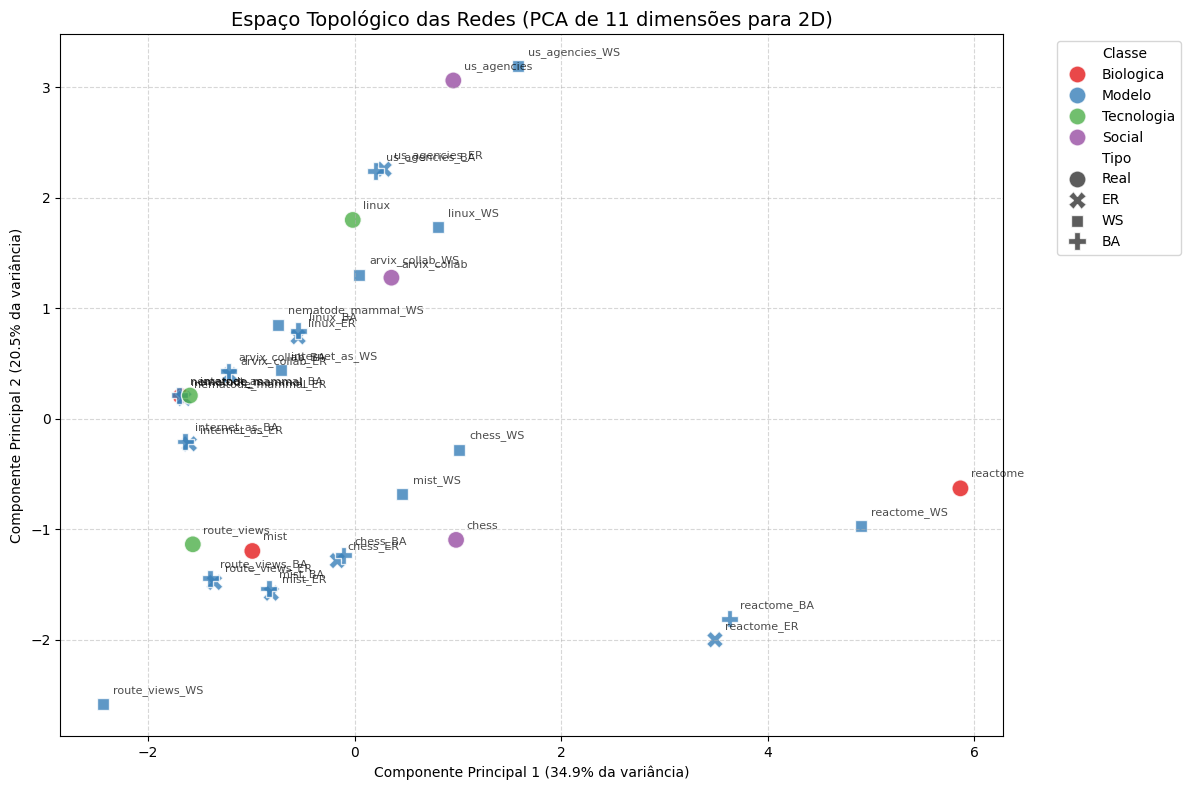

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plotar
plt.figure(figsize=(12, 8))

# Usamos o seaborn para colorir por 'Classe' e mudar o formato (marcador) por 'Tipo'
sns.scatterplot(
    data=df_pca, 
    x='Componente 1', 
    y='Componente 2', 
    hue='Classe',       # Cores diferentes para Bio, Tech, Social, Modelos
    style='Tipo',       # Bolinhas para Reais, X para ER, Quadrados para WS...
    s=150,              # Tamanho dos pontos
    palette='Set1',     # Paleta de cores
    alpha=0.8
)

# Colocar os nomes das redes ao lado dos pontos
for i in range(df_pca.shape[0]):
    plt.text(df_pca['Componente 1'][i] + 0.1, 
             df_pca['Componente 2'][i] + 0.1, 
             df_pca['Rede'][i], 
             fontsize=8, alpha=0.7)

# Títulos e formatação
plt.title('Espaço Topológico das Redes (PCA de 11 dimensões para 2D)', fontsize=14)
plt.xlabel(f'Componente Principal 1 ({pca.explained_variance_ratio_[0]*100:.1f}% da variância)')
plt.ylabel(f'Componente Principal 2 ({pca.explained_variance_ratio_[1]*100:.1f}% da variância)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

### Classificação KNN (K-Nearest Neighbors)
Finalmente, configuramos e utilizamos um classificador KNN (`KNeighborsClassifier`).

Nesta abordagem, o conjunto de dados artificiais (ER, WS, BA) servirá de base de treinamento, definindo regiões no espaço paramétrico para cada classe de rede. O classificador avalia cada rede real como entrada não vista e prediz a qual família de modelo gerador a topologia real mais se assemelha através do cômputo da distância dos *K* vizinhos mais próximos no espaço das características da rede.

In [6]:
from sklearn.neighbors import KNeighborsClassifier

# Definição do treino (redes artificias que criamos)
df_treino = df[df['tipo'] != 'Real'].copy()
X_train = df_treino[features]
y_train = df_treino['tipo']

# Definição do teste (nossas redes reais)
df_teste = df[df['tipo'] == 'Real'].copy()
X_test = df_teste[features]
nomes_redes = df_teste['nome'].values
classes_reais = df_teste['classe'].values

# Normalização dos dados
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Treino e Predição com KNN
k = 3
model = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

print(f"--- Resultados da Classificação KNN (K={k}) ---\n")
print(f"{'NOME DA REDE':<20} | {'DOMÍNIO':<12} | {'KNN PREVIU O MODELO':<20}")
print("-" * 58)

for i in range(len(y_pred)):
    print(f"{nomes_redes[i]:<20} | {classes_reais[i]:<12} | {y_pred[i]}")

--- Resultados da Classificação KNN (K=3) ---

NOME DA REDE         | DOMÍNIO      | KNN PREVIU O MODELO 
----------------------------------------------------------
mist                 | Biologica    | BA
nematode_mammal      | Biologica    | BA
reactome             | Biologica    | BA
linux                | Tecnologia   | BA
internet_as          | Tecnologia   | BA
route_views          | Tecnologia   | BA
us_agencies          | Social       | BA
chess                | Social       | ER
arvix_collab         | Social       | ER


### Conclusão

A hipótese inicial de que redes do mesmo tipo (biológica, social e tecnológica) seguem o mesmo modelo topológico **não se sustenta** perante os dados obtidos. 

Portanto, concluímos que **o contexto empírico da rede (seu domínio ou classe) não determina intrinsecamente o seu modelo matemático de geração.** Redes de campos de estudo distintos podem ter a mesma assinatura estrutural, enquanto redes da mesma categoria podem seguir regras topológicas completamente diferentes.